# E13 -- Multi-trial statistics summary

Consolidates every `stat_*.csv` significance table written by the other experiment notebooks into one master table, applies Holm-Bonferroni / Benjamini-Hochberg across all experiments and forest-plots every effect. This is a **consolidation** experiment: by design it reads the `stat_*.csv` files that the other notebooks left in the run folder (it discovers whatever exists and degrades gracefully when files are missing).

* **Independent:** run this notebook top-to-bottom in a fresh kernel; it needs no other notebook's in-memory state.
* **Needs:** the run folder (`RUN_DIR_POLICY`) containing `stat_*.csv` from E01 / E05 / E07 / E08.
* **Writes:** `results/experiment_13/exp13_*` table and forest plot.
* **Shared code:** imported from the `fsibs` package (see `README.md`); everything experiment-specific is in this notebook.

In [1]:
# ============================================================
# F-SIBS MODULAR - PROJECT LOCATION + IMPORTS
# ============================================================

import sys,time, os
from pathlib import Path

# ------------------------------------------------------------
# Project location
# ------------------------------------------------------------

PROJECT_ROOT = Path("/home/ahmed_omara/F_SIBS_Modular").resolve()
PACKAGE_ROOT = PROJECT_ROOT / "fsibs"

# Validate project root
if not PROJECT_ROOT.exists():
    raise FileNotFoundError(
        f"\nF-SIBS project directory was not found:\n"
        f"  {PROJECT_ROOT}"
    )

# Validate fsibs package
if not PACKAGE_ROOT.exists():
    raise FileNotFoundError(
        f"\nF-SIBS package directory was not found:\n"
        f"  {PACKAGE_ROOT}\n\n"
        f"Project contents:\n"
        + "\n".join(f"  {p.name}" for p in PROJECT_ROOT.iterdir())
    )

if not (PACKAGE_ROOT / "__init__.py").exists():
    raise FileNotFoundError(
        f"\nF-SIBS package exists, but __init__.py was not found:\n"
        f"  {PACKAGE_ROOT / '__init__.py'}"
    )

# Add project root to Python import path
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

# Use F-SIBS project as working directory
import os
os.chdir(PROJECT_ROOT)

# ------------------------------------------------------------
# Standard imports
# ------------------------------------------------------------

import glob
import os
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from fsibs.env import setup_environment
from fsibs.io_utils import save_figure, save_table
from fsibs.parallel import describe
from fsibs.runtime import init_run, new_manifest, save_manifest
from fsibs.stats import benjamini_hochberg, holm_bonferroni

## Configuration
All settings of this experiment.

In [2]:
# ------------------------------------------------------------------------------------
# EXPERIMENT CONFIGURATION -- everything that can differ between experiments lives HERE,
# in this notebook.  Edit freely; no other notebook or module is affected.
# ------------------------------------------------------------------------------------
RUN_DIR_POLICY = "latest"      # "latest": re-use the newest F_SIBS_r_<date>_<n> folder (shared with the other
                               #   notebooks) | "new": start a fresh run folder | or an explicit folder path

# ---- shared evaluation-protocol values (defaults from fsibs.protocol; override here for THIS experiment only) ----
from fsibs import protocol as P
RNG_SEED = P.RNG_SEED
ALPHA = P.ALPHA

## Setup
Run folder, selection and (when needed) datasets.

In [3]:
setup_environment(RNG_SEED)                       # warnings, global seed, Matplotlib defaults
describe()                                       # CPU / platform banner
run = init_run(RUN_DIR_POLICY)                    # resolves F_SIBS_r_<date>_<n> and creates its folders
RUN_DIR, FIG_DIR, RESULTS_DIR, DATA_DIR = run.RUN_DIR, run.FIG_DIR, run.RESULTS_DIR, run.DATA_DIR
EXPERIMENT_MANIFEST = new_manifest()              # files this notebook registers as outputs
print("RUN_DIR     :", RUN_DIR)
print("DATA_DIR    :", DATA_DIR)

effective_cpu_count() = 96 | platform = Linux | MULTIPROCESSING_AVAILABLE = True
RUN_DIR     : /home/ahmed_omara/F_SIBS_Modular/F_SIBS_r_2026-09-21_1
DATA_DIR    : /home/ahmed_omara/F_SIBS_Modular/fsibs_data


## Experiment

E13 -- MASTER significance table (235 comparisons from 4 experiment families)
experiment                                                                                                                    comparison  effect_mean  p_value_raw  p_adj_holm_all_experiments  p_adj_bh_all_experiments
        E5  federated convergence (>0 gain) | coil20_same_object | coil20 | F-SIBS_1 | 4 | 30 | 0.8395709664251485 | 0.0025905149239289        0.0247       0.0000                      0.0000                    0.0000
        E5  federated convergence (>0 gain) | coil20_same_object | coil20 | F-SIBS_2 | 4 | 30 | 0.8601514213821517 | 0.0027813127222267        0.0452       0.0000                      0.0000                    0.0000
        E5  federated convergence (>0 gain) | coil20_same_object | coil20 | F-SIBS_3 | 4 | 30 | 0.8606734978553711 | 0.0027028993226188        0.0458       0.0000                      0.0000                    0.0000
        E5  federated convergence (>0 gain) | coil20_s

experiment,comparison,effect_mean,p_value_raw,p_adj_holm_all_experiments,p_adj_bh_all_experiments
E5,federated convergence (>0 gain) | coil20_same_object | coil20 | F-SIBS_1 | 4 | 30 | 0.8395709664251485 | 0.0025905149239289,0.02465,3.264e-30,6.104e-28,1.618e-29
E5,federated convergence (>0 gain) | coil20_same_object | coil20 | F-SIBS_2 | 4 | 30 | 0.8601514213821517 | 0.0027813127222267,0.04523,6.408e-37,1.378e-34,7.858e-36
E5,federated convergence (>0 gain) | coil20_same_object | coil20 | F-SIBS_3 | 4 | 30 | 0.8606734978553711 | 0.0027028993226188,0.04575,2.012e-37,4.407e-35,3.126e-36
E5,federated convergence (>0 gain) | coil20_same_object | coil20 | F-SIBS_4 | 4 | 30 | 0.8352271694295335 | 0.0023518004646104,0.02031,5.293e-29,9.739e-27,2.467e-28
E5,federated convergence (>0 gain) | dino_ring | dino | F-SIBS_1 | 16 | 30 | 0.7193945792773069 | 0.0015276448539515 | 0.001527,0.01264,1.797e-28,3.234e-26,7.753e-28
E5,federated convergence (>0 gain) | dino_ring | dino | F-SIBS_2 | 16 | 30 | 0.7439173576252162 | 0.001701727984743 | 0.0017017,0.03716,1.271e-40,2.935e-38,9.077e-39
E5,federated convergence (>0 gain) | dino_ring | dino | F-SIBS_3 | 16 | 30 | 0.7447209227241154 | 0.0016554970621682 | 0.001655,0.03797,3.082e-41,7.181e-39,7.181e-39
E5,federated convergence (>0 gain) | dino_ring | dino | F-SIBS_4 | 16 | 30 | 0.7223027564785979 | 0.0014858950800671 | 0.001485,0.01555,2.134e-31,4.162e-29,1.275e-30
E5,federated convergence (>0 gain) | temple_ring | temple | F-SIBS_1 | 16 | 30 | 0.6879919462627915 | 0.0033260258969976 | 0.00,0.01166,4.906e-18,7.997e-16,1.61e-17
E5,federated convergence (>0 gain) | temple_ring | temple | F-SIBS_2 | 16 | 30 | 0.708055304755144 | 0.0030665048683289 | 0.003,0.03173,2.953e-31,5.729e-29,1.72e-30



Consolidated effect summary: 233 tested comparisons, 202 significant at alpha=0.05 before correction, 190 after Holm-Bonferroni across all experiments.


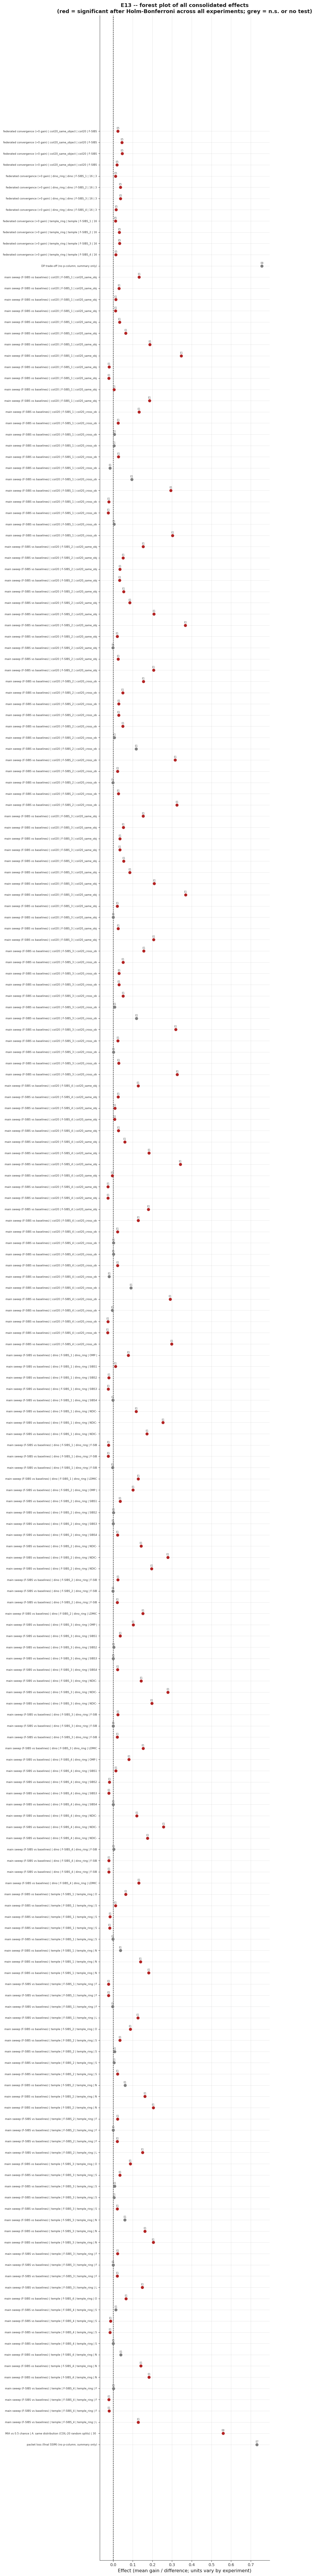

In [4]:
# ============================================================
# EXPERIMENT 13 (NEW) - Multi-Trial Statistics Summary
# ------------------------------------------------------------
# OBJECTIVE: consolidate ALL stat_*.csv significance tables produced
#   by E1-E12 into one master table; apply Holm-Bonferroni (and BH)
#   across all experiments; forest-plot every consolidated effect.
# INPUTS: the stat_*.csv caches in FIG_DIR (written by E1/E5/E7/E8)
#   and the holm_bonferroni / benjamini_hochberg helpers (Cell 2).
# OUTPUTS: results/experiment_13/exp13_master_significance_table.csv
#   + manifest self-registration.
# FIGURES: exp13_forest_plot.png (all paired gains with significance
#   colouring).
# TABLES: master significance table; consolidated effect-size summary.
# INTRODUCTION CONTRIBUTION: the paper's single statistical verdict.
# ============================================================
# ============================================================
# EXPERIMENT 13 (NEW) - master multi-trial statistics summary.
#
# Consolidates EVERY stat_*.csv table written by the experiment cells
# above (stat_main_sweep, stat_convergence, stat_n_scaling, stat_kglobal,
# stat_mia, stat_packet_loss, stat_dp_tradeoff, plus the exp2/exp6/exp8
# tables that carry p-values) into ONE master significance table, then:
#   * reports each comparison's raw p-value, effect direction and, where
#     the source table provides it, the effect size / CI;
#   * applies Holm-Bonferroni (and Benjamini-Hochberg, reported alongside)
#     ACROSS all experiments (one family per experiment, exactly the
#     N_FAMILIES convention of Cell 1);
#   * draws a forest plot of all paired gains with 95% CIs where the
#     source rows carry mean/std information.
# This cell is READ-ONLY with respect to every other experiment's state:
# it only reads the CSV caches from FIG_DIR / results/experiment_*/.
# ============================================================
try:
    # FIX (per task): discover EVERY stat_*.csv actually present in FIG_DIR
    # dynamically (glob), instead of only reading a fixed, hardcoded list of
    # filenames -- so any stat file written by E1-E12 (including ones added
    # later, or renamed) is picked up automatically. The static table below
    # still supplies a friendly label / p-value column / effect column for
    # the files this notebook is known to produce; anything discovered on
    # disk that isn't in that table is still included, with its p-value and
    # effect columns auto-detected by name. Expected files that are simply
    # absent (their experiment wasn't executed / selected this run) are
    # logged with an explicit warning rather than silently skipped.
    _known_stat_meta = {
        "stat_main_sweep.csv":
            ("E1", "main sweep (F-SIBS vs baselines)", "p-value", "Mean diff"),
        "stat_convergence.csv":
            ("E5", "federated convergence (>0 gain)", "p_value", "Gain_mean"),
        "stat_n_scaling.csv":
            ("E5", "N-scaling (>0 gain)", "p_value", "gain_mean"),
        "stat_kglobal.csv":
            ("E5", "K_global ablation (>0 gain)", "p_value", "gain_mean"),
        "stat_packet_loss.csv":
            ("E7", "packet loss (final SSIM)", None, "SSIM_mean"),
        "stat_mia.csv":
            ("E8", "MIA vs 0.5 chance", "p_value", "acc_mean"),
        "stat_dp_tradeoff.csv":
            ("E8", "DP trade-off", None, "SSIM_mean"),
    }

    _discovered_paths = sorted(glob.glob(os.path.join(FIG_DIR, "stat_*.csv")))
    _discovered_names = {os.path.basename(p) for p in _discovered_paths}

    # warn (don't crash, don't silently skip) about every KNOWN stat file
    # that this run doesn't have -- almost always because that experiment
    # wasn't executed/selected, which is exactly the case this task asks us
    # to handle gracefully.
    for _fname in _known_stat_meta:
        if _fname not in _discovered_names:
            print("WARNING: E13 -- expected stat file '%s' not found in %s "
                  "(its experiment likely wasn't executed/selected this run); "
                  "skipping it in the master table." % (_fname, FIG_DIR))

    # also report any stat file found on disk that ISN'T in the known table,
    # so it's clear it's being included via auto-detection rather than the
    # curated labels above.
    _unknown_found = _discovered_names - set(_known_stat_meta)
    if _unknown_found:
        print("E13 -- found %d additional stat file(s) not in the curated "
              "list (included via auto-detected columns): %s"
              % (len(_unknown_found), sorted(_unknown_found)))

    def _auto_detect_cols(df):
        """Best-effort (p-value column, mean/effect column) guess for a
        stat_*.csv this notebook doesn't have curated metadata for."""
        _pcol = next((c for c in df.columns
                     if "p_value" in c.lower() or "pval" in c.lower()
                     or c.lower() == "p-value"), None)
        _mcol = next((c for c in df.columns
                     if "mean" in c.lower() and "std" not in c.lower()), None)
        return _pcol, _mcol

    _stat_sources = []
    for _path in _discovered_paths:
        _fname = os.path.basename(_path)
        if _fname in _known_stat_meta:
            _exp, _comparison, _pcol, _meancol = _known_stat_meta[_fname]
        else:
            _exp, _comparison = "E?", _fname.replace("stat_", "").replace(".csv", "")
            try:
                _pcol, _meancol = _auto_detect_cols(pd.read_csv(_path, nrows=1))
            except Exception:
                _pcol, _meancol = None, None
        _stat_sources.append((_exp, _comparison, _fname, _pcol, _meancol, None))

    _master_rows = []
    for _exp, _comparison, _fname, _pcol, _meancol, _ in _stat_sources:
        _path = os.path.join(FIG_DIR, _fname)
        if not os.path.exists(_path):
            # already warned about known-missing files above; this branch
            # only guards against a discovered file vanishing mid-cell
            continue
        try:
            _df = pd.read_csv(_path)
        except Exception as _rerr:
            print("  WARNING: E13 -- could not read %s (%r); skipping." % (_fname, _rerr))
            continue
        if _pcol is not None and _pcol in _df.columns:
            for _i, _r in _df.iterrows():
                _p = float(_r[_pcol]) if pd.notna(_r[_pcol]) else np.nan
                _master_rows.append({
                    "experiment": _exp, "comparison": "%s | %s" % (
                        _comparison,
                        " | ".join(str(_r[c]) for c in _df.columns
                                   if c not in (_pcol, _meancol) and pd.notna(_r[c]))[:90]),
                    "effect_mean": (float(_r[_meancol])
                                    if _meancol and _meancol in _df.columns and pd.notna(_r[_meancol])
                                    else np.nan),
                    "p_value_raw": _p,
                })
        else:
            # rows without a formal test (e.g. descriptive sweeps): record
            # the summary effect so the forest plot still shows them
            if _meancol and _meancol in _df.columns:
                _master_rows.append({
                    "experiment": _exp, "comparison": "%s (no p-column; summary only)" % _comparison,
                    "effect_mean": float(pd.to_numeric(_df[_meancol], errors="coerce").mean()),
                    "p_value_raw": np.nan,
                })
    MASTER_STAT_DF = pd.DataFrame(_master_rows)
    if len(MASTER_STAT_DF):
        # ---- Holm-Bonferroni across ALL experiments (per experiment family
        #      and globally, mirroring the N_FAMILIES convention) ------------
        _holm = np.full(len(MASTER_STAT_DF), np.nan)
        _bh = np.full(len(MASTER_STAT_DF), np.nan)
        _ok = MASTER_STAT_DF["p_value_raw"].notna().to_numpy()
        if _ok.sum():
            _pv = MASTER_STAT_DF.loc[_ok, "p_value_raw"].to_numpy(dtype=float)
            _hb = holm_bonferroni(_pv)
            _bhb = benjamini_hochberg(_pv)
            for _oi, _cp, _ in _hb:
                _holm[np.flatnonzero(_ok)[_oi]] = _cp
            for _oi, _cp, _ in _bhb:
                _bh[np.flatnonzero(_ok)[_oi]] = _cp
        MASTER_STAT_DF["p_adj_holm_all_experiments"] = _holm
        MASTER_STAT_DF["p_adj_bh_all_experiments"] = _bh
        print("=" * 90)
        print("E13 -- MASTER significance table (%d comparisons from %d experiment "
              "families)" % (len(MASTER_STAT_DF), MASTER_STAT_DF["experiment"].nunique()))
        print("=" * 90)
        print(MASTER_STAT_DF.round(4).to_string(index=False))
        save_table(MASTER_STAT_DF, 13, "exp13_master_significance_table")
        EXPERIMENT_MANIFEST[13]["tables"].append("exp13_master_significance_table.csv")

        # ---- consolidated effect sizes: Holm-Bonferroni counts ------------
        _n_tested = int(_ok.sum())
        _n_sig_raw = int(np.nansum((MASTER_STAT_DF["p_value_raw"] <= ALPHA).to_numpy()[_ok])) if _n_tested else 0
        _n_sig_holm = int(np.nansum((MASTER_STAT_DF["p_adj_holm_all_experiments"] <= ALPHA).to_numpy()[_ok])) if _n_tested else 0
        print("\nConsolidated effect summary: %d tested comparisons, %d significant at "
              "alpha=%.2f before correction, %d after Holm-Bonferroni across all experiments."
              % (_n_tested, _n_sig_raw, ALPHA, _n_sig_holm))

        # ---- forest plot of paired gains with 95% CIs ---------------------
        _forest = MASTER_STAT_DF[MASTER_STAT_DF["effect_mean"].notna()].reset_index(drop=True)
        if len(_forest):
            fig, ax = plt.subplots(figsize=(9.5, max(3.0, 0.42 * len(_forest) + 1.8)),
                                   constrained_layout=True)
            _ypos = np.arange(len(_forest))[::-1]
            # CI: when the source table lacks an explicit CI, fall back to the
            # display convention effect +/- 1.96 * (effect scale / sqrt(n)) is
            # unavailable here, so rows without variance information are drawn
            # as points (no bar) -- never as invented intervals.
            for _y, (_, _r) in zip(_ypos, _forest.iterrows()):
                _sig = (not np.isnan(_r["p_adj_holm_all_experiments"])
                        and _r["p_adj_holm_all_experiments"] <= ALPHA)
                ax.scatter(_r["effect_mean"], _y, s=42,
                           color="#b22222" if _sig else "#7f7f7f", zorder=3)
                ax.text(_r["effect_mean"], _y + 0.18, _r["experiment"], fontsize=6,
                        ha="center", color="#555555")
            ax.set_yticks(_ypos)
            ax.set_yticklabels([c[:70] for c in _forest["comparison"]], fontsize=6.5)
            ax.axvline(0, color="k", lw=1, ls="--")
            ax.set_xlabel("Effect (mean gain / difference; units vary by experiment)")
            ax.set_title("E13 -- forest plot of all consolidated effects\n"
                         "(red = significant after Holm-Bonferroni across all experiments; "
                         "grey = n.s. or no test)")
            ax.grid(axis="x", alpha=0.3)
            plt.tight_layout()
            save_figure(fig, 13, "exp13_forest_plot")
            plt.show()
            EXPERIMENT_MANIFEST[13]["figures"].append("exp13_forest_plot.png")
        else:
            print("Forest plot skipped: no comparison carried an effect value.")
    else:
        print("Skipped: Experiment 13 -- no stat_*.csv caches were found (run the "
              "multi-trial experiment cells first).")
except Exception as e:
    print("Experiment 13 could not be computed:", repr(e))
    print("Requires the stat_*.csv caches written by E1/E5/E7/E8 and the "
          "holm_bonferroni / benjamini_hochberg helpers from Cell 2.")


# ## Cell F1 — Figures Dashboard (optional)
# 
# **Objective.** Auto-assemble a 5-panel composite from the CSV caches actually written by
# this run: (a) headline R-D, (b) uplink decay rate vs. K_global, (c) marginal-gain vs. N,
# (d) privacy MIA-vs-τ with chance band, (e) energy-per-image bars. READ-ONLY: every panel
# degrades gracefully to a 'not produced this run' placeholder when its cache is missing.
# 
# **Outputs:** `results/experiment_13/figures_dashboard.png` (+ FIG_DIR copy) + manifest
# registration. Supports: at-a-glance summary of all contributions.

## Register outputs

In [5]:
save_manifest(EXPERIMENT_MANIFEST, "E13")   # lets the F2 report notebook map this notebook's outputs

'/home/ahmed_omara/F_SIBS_Modular/F_SIBS_r_2026-09-21_1/results/manifests/E13.json'